In [ ]:
# ** FIX: REVISIT THE TRAIN-TEST SPLIT STRATEGY**
#random forest fit on climatology of different topographic and environmental variables to determine weights for kmeans clustering
#permutation feature importance is calculated based on r2 values

import os
import numpy as np
import pandas as pd
import rasterio
import rioxarray as rxr
import xarray as xr
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import gc

In [13]:
temp_file_path = r"..\Data\Processed\Spatial_clustering\Temp"
file_list = [f for f in os.listdir(temp_file_path) if f.endswith(".tif")]

sample_raster = rxr.open_rasterio(r"..\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif")

data_arrays = {}
for file in file_list:
    var_name = file.split(".")[0]
    da = rxr.open_rasterio(os.path.join(temp_file_path, file), masked=True)
    da = da.rio.reproject_match(sample_raster)
    
    if da.shape[0] == 1:
        da = da.squeeze('band', drop=True)
    
    data_arrays[var_name] = da

stacked_ds = xr.Dataset(data_arrays)
del data_arrays, sample_raster
gc.collect()

6451

In [14]:
#check a few rasters by visualizing
#stacked_ds.MODIS_2_lst_d_clim.plot()

In [15]:
y_dim = stacked_ds.rio.y_dim  
x_dim = stacked_ds.rio.x_dim

valid_mask = None
for var in stacked_ds.data_vars:
    var_mask = ~np.isnan(stacked_ds[var].values)
    valid_mask = var_mask if valid_mask is None else valid_mask & var_mask

stacked_ds_dict = {}
for var in stacked_ds.data_vars:
    stacked_ds_dict[var] = stacked_ds[var].values[valid_mask].flatten().astype('float32')

stacked_df = pd.DataFrame(stacked_ds_dict, dtype='float32')
del stacked_ds_dict, var_mask
gc.collect()

# %%
# Store spatial info
spatial_coords = {
    'x': stacked_ds[x_dim].values,
    'y': stacked_ds[y_dim].values,
    'crs': stacked_ds.rio.crs,
    'transform': stacked_ds.rio.transform(),
    'shape': (len(stacked_ds[y_dim]), len(stacked_ds[x_dim]))
}

del stacked_ds, valid_mask, y_dim, x_dim
gc.collect()



389

In [16]:
#3. Standardize the variables for RF

# Train-test split and standardization
random_state_num = 41
target = 'prec_clim_resampled'

train_df, test_df = train_test_split(stacked_df, test_size=0.3, random_state=random_state_num)
del stacked_df
gc.collect()

std_scaler = StandardScaler()
X_train = train_df.drop(columns=[target])
y_train = train_df[target].values
del train_df

X_train_scaled = std_scaler.fit_transform(X_train).astype('float32')
feature_names = X_train.columns.tolist()
del X_train
gc.collect()

X_test = test_df.drop(columns=[target])
y_test = test_df[target].values
del test_df

X_test_scaled = std_scaler.transform(X_test).astype('float32')
del X_test, std_scaler
gc.collect()

0

In [17]:
# 4. Fit random forest model
# uncomment and run this code to get hyperparameter tuning results (takes about 14.5 hours with 5 cores)
# HPT results: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}
# Best Mean CV Score (Train): 0.9953
# Independent Test R^2 Score: 0.9962
# 1 fit failed out of the total 5(cross folds) * 50 (iterations) = 250 fits due to memory time out



# param_dist_rf = {
#     'n_estimators': [100, 200, 300, 500], 
#     'max_features': ['sqrt', 'log2'],
#     'max_depth': [None, 10, 20, 30], 
#     'min_samples_split': [2, 5, 10], 
#     'min_samples_leaf': [1, 2, 4] 
# }

# # Calculate half of the available CPU cores
# n_cores = 5

# rf = RandomForestRegressor(random_state=42)
# rf_search = RandomizedSearchCV(
#     estimator=rf, 
#     param_distributions=param_dist_rf, 
#     n_iter=50,  
#     cv=5, 
#     verbose=3, 
#     random_state=random_state_num, 
#     n_jobs=n_cores
# )
# rf_search.fit(X_train, y_train)
# best_rf_model = rf_search.best_estimator_

# # 4. Final Validation Scores
# print(f"\nBest RF Hyperparameters: {rf_search.best_params_}")
# print(f"Best Mean CV Score (Train): {rf_search.best_score_:.4f}")
# print(f"Independent Test R^2 Score: {best_rf_model.score(X_test, y_test):.4f}")

In [18]:
#fit the best rf model to get validation scores

rf_parameters = {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}
rf_model = RandomForestRegressor(**rf_parameters, random_state=random_state_num, n_jobs = 3)
rf_fit = rf_model.fit(X_train_scaled, y_train)

del X_train_scaled, y_train
gc.collect()

y_pred = rf_fit.predict(X_test_scaled)

mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
bias = np.mean(y_pred - y_test)

print(f"Validation MAE: {mae:.4f}")
print(f"Validation RMSE: {rmse:.4f}")
print(f"Validation R^2: {r2:.4f}")
print(f"Validation Bias: {bias:.4f}")
print(f"In units of annual prec: mm")

del y_pred, rf_parameters, rf_model
gc.collect()

Validation MAE: 22.7240
Validation RMSE: 54.2302
Validation R^2: 0.9962
Validation Bias: -0.6718
In units of annual prec: mm


24

In [19]:
#5. Get permutation feature importance 
# to get weights of features in rf fit

pfi_test1 = permutation_importance(rf_fit, X_test_scaled, y_test, scoring = 'r2', random_state = random_state_num, n_repeats = 5, n_jobs = 1, max_samples = 0.40)


{'DEM_1km_aspect_mean': np.float64(0.00018428072712370903), 'DEM_1km_elevation_max': np.float64(0.005166328763909989), 'DEM_1km_elevation_mean': np.float64(0.004142497128929112), 'DEM_1km_elevation_min': np.float64(0.004991740158082148), 'DEM_1km_elevation_std': np.float64(0.0014118411596446556), 'DEM_1km_slope_mean': np.float64(0.002027971815096774), 'dem_smoothed': np.float64(0.08871982488183769), 'ERA5L_2_dewpoint_temperature_clim_resampled': np.float64(0.18019193279174067), 'ERA5L_2_soil_moisture_clim_resampled': np.float64(0.25737416855886985), 'ERA5L_2_surface_pressure_clim_resampled': np.float64(0.025018306816928737), 'ERA5L_2_total_evaporation_clim_resampled': np.float64(0.07238450101948386), 'ERA5L_2_wind_speed_clim_resampled': np.float64(0.09897566551445491), 'fetch_dir_1000m_resampled': np.float64(0.0026822901644571796), 'fetch_dir_500m_resampled': np.float64(0.0007800059581263951), 'fetch_dist_1000m_resampled': np.float64(0.029914190331583223), 'fetch_dist_500m_resampled': 

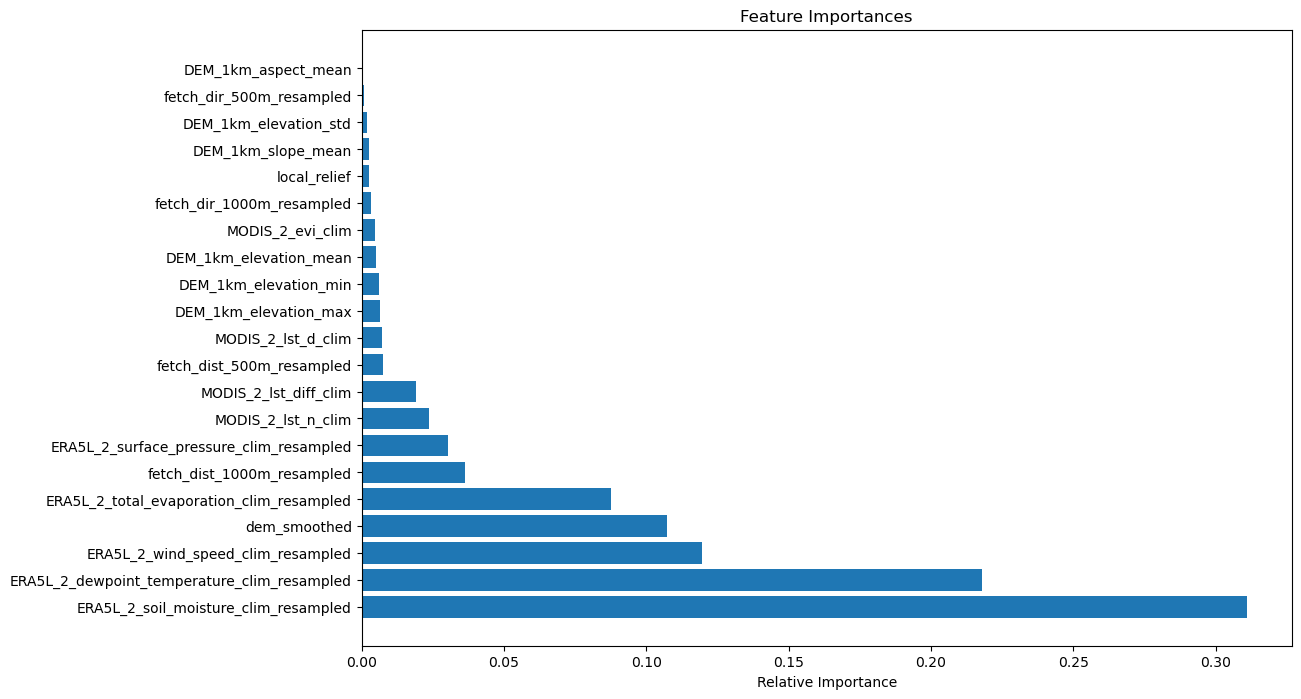

In [20]:
#get feature importances in a dict with feature names as keys and importances as values
feature_importances_abs = dict(zip(feature_names, pfi_test1.importances_mean))

#calculate relative importance 
feature_importances = {k: v / sum(feature_importances_abs.values()) for k, v in feature_importances_abs.items()}

#sort the dict by values in descending order
feature_importances = dict(sorted(feature_importances.items(), key=lambda item: item[1], reverse=True))
feature_importances_df = pd.DataFrame.from_dict(feature_importances, orient='index', columns=['importance'])
feature_importances_df.to_csv(r'..\Data\Processed\Spatial_clustering\feature_importances.csv')
print(feature_importances_abs)
print(feature_importances)

#plot the feature importances
plt.figure(figsize=(12,8))
plt.barh(list(feature_importances.keys()), list(feature_importances.values()))
plt.xlabel('Relative Importance')
plt.title('Feature Importances')
plt.show()


{'DEM_1km_aspect_mean': np.float64(0.5150692548033404), 'DEM_1km_elevation_max': np.float64(26.873697404472672), 'DEM_1km_elevation_mean': np.float64(24.463471337592075), 'DEM_1km_elevation_min': np.float64(26.545076461013686), 'DEM_1km_elevation_std': np.float64(8.604539808232747), 'DEM_1km_slope_mean': np.float64(11.542879502044974), 'dem_smoothed': np.float64(154.27365034709334), 'ERA5L_2_dewpoint_temperature_clim_resampled': np.float64(217.58613396210052), 'ERA5L_2_soil_moisture_clim_resampled': np.float64(193.47645886361556), 'ERA5L_2_surface_pressure_clim_resampled': np.float64(64.99386960612202), 'ERA5L_2_total_evaporation_clim_resampled': np.float64(125.66454964678933), 'ERA5L_2_wind_speed_clim_resampled': np.float64(145.4046129236271), 'fetch_dir_1000m_resampled': np.float64(13.274499378249956), 'fetch_dir_500m_resampled': np.float64(5.011950825528102), 'fetch_dist_1000m_resampled': np.float64(61.2266497429528), 'fetch_dist_500m_resampled': np.float64(30.62885621687598), 'loca

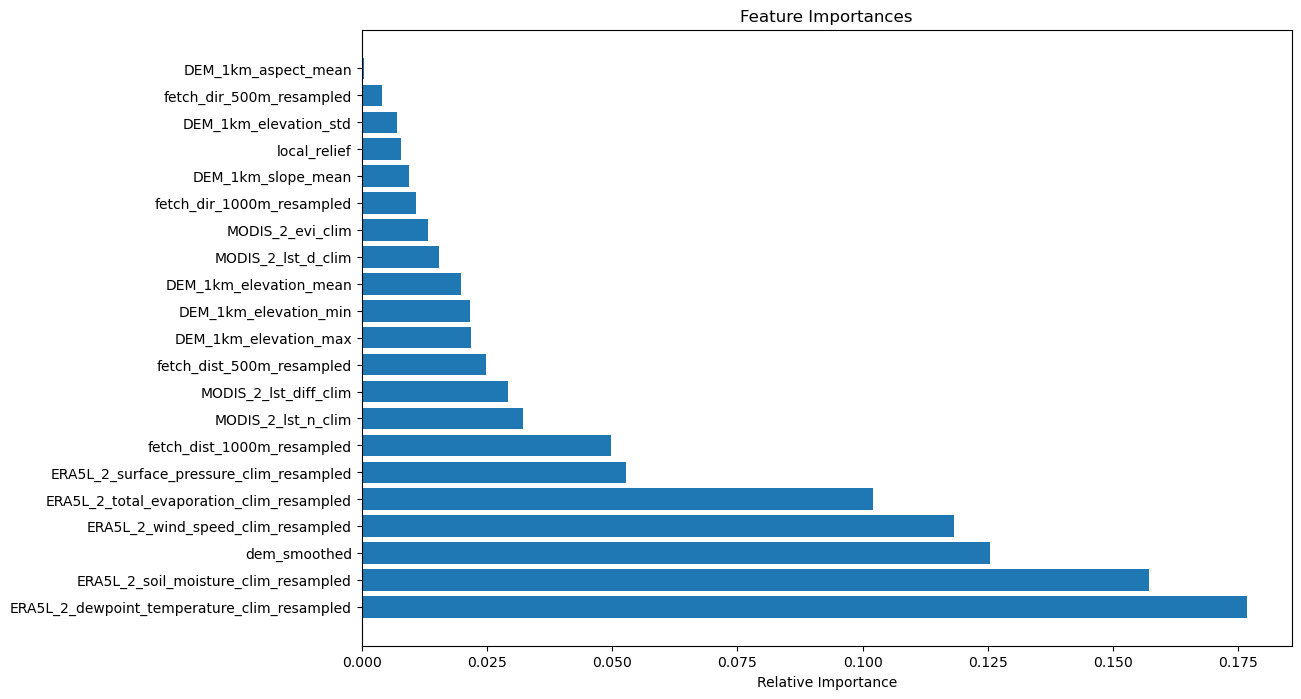

In [22]:
#trying a different approach to pfi using mae as the scoring metric
pfi_test2 = permutation_importance(rf_fit, X_test_scaled, y_test, scoring = 'neg_mean_absolute_error', random_state = random_state_num, n_repeats = 5, n_jobs = 1, max_samples = 0.40)

feature_importances_abs2 = dict(zip(feature_names, pfi_test2.importances_mean))

#calculate relative importance 
feature_importances2 = {k: v / sum(feature_importances_abs2.values()) for k, v in feature_importances_abs2.items()}

#sort the dict by values in descending order
feature_importances2 = dict(sorted(feature_importances2.items(), key=lambda item: item[1], reverse=True))
feature_importances_df2 = pd.DataFrame.from_dict(feature_importances2, orient='index', columns=['importance'])
feature_importances_df2.to_csv(r'..\Data\Processed\Spatial_clustering\feature_importances2.csv')
print(feature_importances_abs2)
print(feature_importances2)

#plot the feature importances
plt.figure(figsize=(12,8))
plt.barh(list(feature_importances2.keys()), list(feature_importances2.values()))
plt.xlabel('Relative Importance')
plt.title('Feature Importances')
plt.show()